# 🏇 Análisis de Jackpot Jockeys

Este cuaderno analiza a los caballos del juego: redes neuronales **13 → 8 → 3 → 3 → 2** entrenadas por
neuroevolución a partir del campeón del simulador F1 (`f1_best_brain.weights.h5`, que era 5 → 5 → 3 → 3 → 2;
las entradas y neuronas nuevas arrancaron con pesos en cero).

La red **no tiene ninguna regla de embestir**: solo decide giro y acelerador a partir de lo que percibe:

| # | Entrada | # | Entrada |
|---|---|---|---|
| 0-4 | 5 sensores de distancia a bordes y vallas | 8 | ¿el rival tiene escudo o furia? |
| 5 | distancia al rival más cercano | 9 | ¿tengo furia? |
| 6 | rumbo hacia ese rival | 10 | ¿tengo turbo? |
| 7 | velocidad relativa del rival | 11 | distancia al barro que tengo adelante |
|  |  | 12 | mi puesto en la carrera (0 = primero) |

Modelos entrenados (la aptitud premia avanzar, terminar rápido y no tropezar ni salirse):
- **💨 corredor**: además castiga ser embestido. Lo usan Relámpago, Canela y Centella.
- **😤 bravo_60 / bravo_100 / bravo_150**: cada embestida dada suma 60, 100 o 150 puntos (máximo 8 por carrera)
  y cada embestida recibida resta 20. Son Trueno (*pícaro*), Pegaso (*bravo*) y Tormenta (*muy bravo*).

**Fuentes de datos** (se regeneran con los scripts de la carpeta):
| Archivo | Script | Contenido |
|---|---|---|
| `logs/entrenamiento_corredor.csv` | `node entrenar.js corredor 300` | Una fila por generación |
| `logs/entrenamiento_bravo_<premio>.csv` | `node entrenar.js bravo 300 <premio>` | Una fila por generación |
| `logs/torneo.csv` | `node torneo.js 600 0.7` | Una fila por caballo y carrera, con poderes al azar |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Estilo oscuro, igual que data.ipynb
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#0f0f0f', 'axes.facecolor': '#1a1a1a',
    'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white',
    'text.color': 'white', 'axes.titlecolor': 'white', 'axes.edgecolor': '#333333',
    'grid.color': '#2a2a2a', 'legend.facecolor': '#1a1a1a', 'legend.edgecolor': '#333333',
    'savefig.facecolor': '#0f0f0f', 'savefig.bbox': 'tight',
})
OUT = Path('analisis'); OUT.mkdir(exist_ok=True)
PERFIL_COLOR = {'corredor': '#4fc3f7', 'bravo': '#ff5252'}
MODELOS = ['corredor', 'bravo_60', 'bravo_100', 'bravo_150']
MODELO_COLOR = {'corredor': '#4fc3f7', 'bravo_60': '#ffd54f', 'bravo_100': '#ff8a3d', 'bravo_150': '#ff5252'}
ESTILOS = ['corredor', 'pícaro', 'bravo', 'muy bravo']
ESTILO_COLOR = {'corredor': '#4fc3f7', 'pícaro': '#ffd54f', 'bravo': '#ff8a3d', 'muy bravo': '#ff5252'}

train = pd.concat([pd.read_csv(f'logs/entrenamiento_{m}.csv') for m in MODELOS], ignore_index=True)
train['modelo'] = np.where(train.perfil == 'corredor', 'corredor', 'bravo_' + train.premio_golpe.astype(str))
torneo = pd.read_csv('logs/torneo.csv')
HORSE_COLOR = dict(zip(torneo.nombre, torneo.color))
HORSE_ORDER = list(dict.fromkeys(torneo.sort_values('caballo').nombre))

# Tiempo relativo al ganador de cada carrera (1.0 = ganó)
torneo['tiempo_rel'] = torneo.tiempo_s / torneo.groupby('carrera').tiempo_s.transform('min')
print(f"Entrenamiento: {len(train)} generaciones | Torneo: {torneo.carrera.nunique()} carreras, {len(torneo)} filas")
torneo.head()

Entrenamiento: 1200 generaciones | Torneo: 600 carreras, 3600 filas


,carrera,seed,tamano,largo_pista,vueltas,obstaculos,caballo,nombre,perfil,estilo,...,progreso_pct,golpes_dados,golpes_recibidos,tropiezos,saltos,salidas,poder_recibido,poder_bloqueado,poder_en_carrera,tiempo_rel
0,1,455407,corta,3081,2,7,1,Backprop,corredor,corredor,...,100,3,2,0,5,0,ninguno,NaN,escudo,1.032747
1,1,455407,corta,3081,2,7,2,Overfitting,bravo,muy bravo,...,100,4,5,2,4,7,escudo,False,escudo,1.372493
2,1,455407,corta,3081,2,7,3,Gradiente,corredor,corredor,...,100,2,2,0,4,0,ninguno,NaN,escudo,1.094147
3,1,455407,corta,3081,2,7,4,Dropout,bravo,bravo,...,100,0,5,0,4,7,ninguno,NaN,escudo,1.330332
4,1,455407,corta,3081,2,7,5,Tanh Tanh,corredor,corredor,...,100,3,1,0,4,0,ninguno,NaN,escudo,1.000000


## 1. Convergencia del entrenamiento

La pista cambia en cada generación (tamaño corta / media / larga y semilla nueva), así que la aptitud es
ruidosa. Usamos media móvil para ver la tendencia. Las aptitudes de cada perfil **no son comparables
entre sí** porque premian cosas distintas; lo que importa es la forma de cada curva.

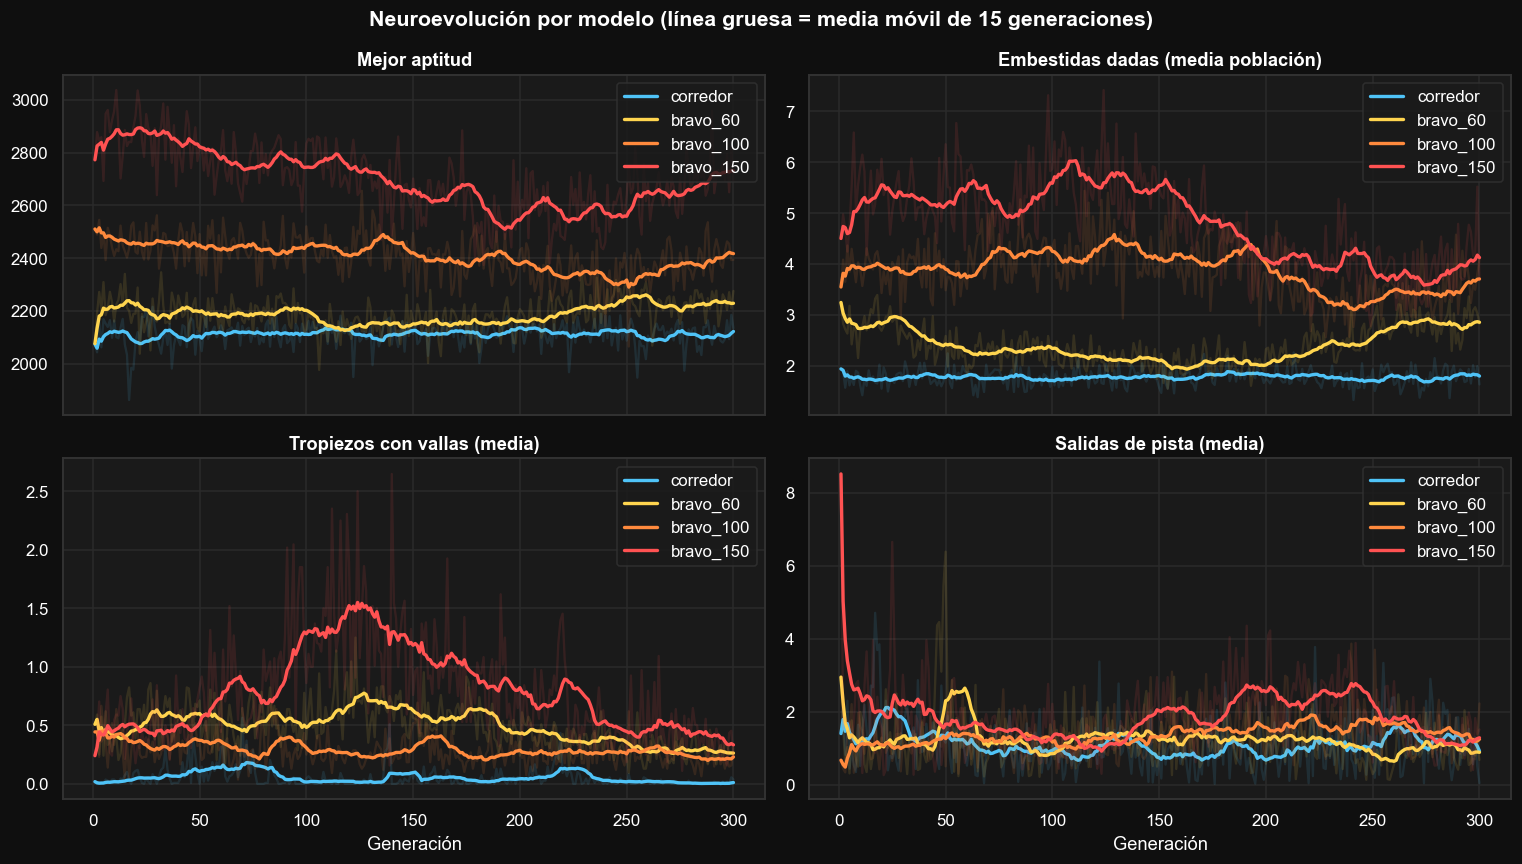

,golpes_inicio,golpes_final,tropiezos_inicio,tropiezos_final,salidas_inicio,salidas_final
modelo,,,,,,
corredor,1.74,1.78,0.04,0.01,1.57,1.15
bravo_60,2.84,2.83,0.52,0.28,1.21,0.99
bravo_100,3.90,3.58,0.35,0.22,1.05,1.39
bravo_150,5.30,4.00,0.47,0.39,2.31,1.20


In [2]:
win = 15
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
metrics = [('best_fitness', 'Mejor aptitud'), ('avg_hits_given', 'Embestidas dadas (media población)'),
           ('avg_stumbles', 'Tropiezos con vallas (media)'), ('avg_falls', 'Salidas de pista (media)')]
for ax, (col, title) in zip(axes.flat, metrics):
    for m in MODELOS:
        g = train[train.modelo == m]
        ax.plot(g.generation, g[col], color=MODELO_COLOR[m], alpha=0.12)
        ax.plot(g.generation, g[col].rolling(win, min_periods=1).mean(), color=MODELO_COLOR[m], lw=2.2, label=m)
    ax.set_title(title, fontweight='bold')
    ax.legend()
for ax in axes[1]: ax.set_xlabel('Generación')
fig.suptitle('Neuroevolución por modelo (línea gruesa = media móvil de 15 generaciones)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig(OUT / '01_convergencia.png'); plt.show()

first, last = train[train.generation <= 30], train[train.generation > train.generation.max() - 30]
pd.DataFrame({
    'golpes_inicio': first.groupby('modelo').avg_hits_given.mean(),
    'golpes_final': last.groupby('modelo').avg_hits_given.mean(),
    'tropiezos_inicio': first.groupby('modelo').avg_stumbles.mean(),
    'tropiezos_final': last.groupby('modelo').avg_stumbles.mean(),
    'salidas_inicio': first.groupby('modelo').avg_falls.mean(),
    'salidas_final': last.groupby('modelo').avg_falls.mean(),
}).reindex(MODELOS).round(2)

## 2. Topología de pesos: ¿a qué le presta atención cada perfil?

Mapa de calor de la primera capa (13 entradas → 8 neuronas ocultas) del mejor cerebro de cada modelo.
Las filas de la 5 a la 12 y las columnas h6-h8 arrancaron en **cero** (el campeón de Python no las tenía),
así que todo su peso fue aprendido en este entrenamiento.

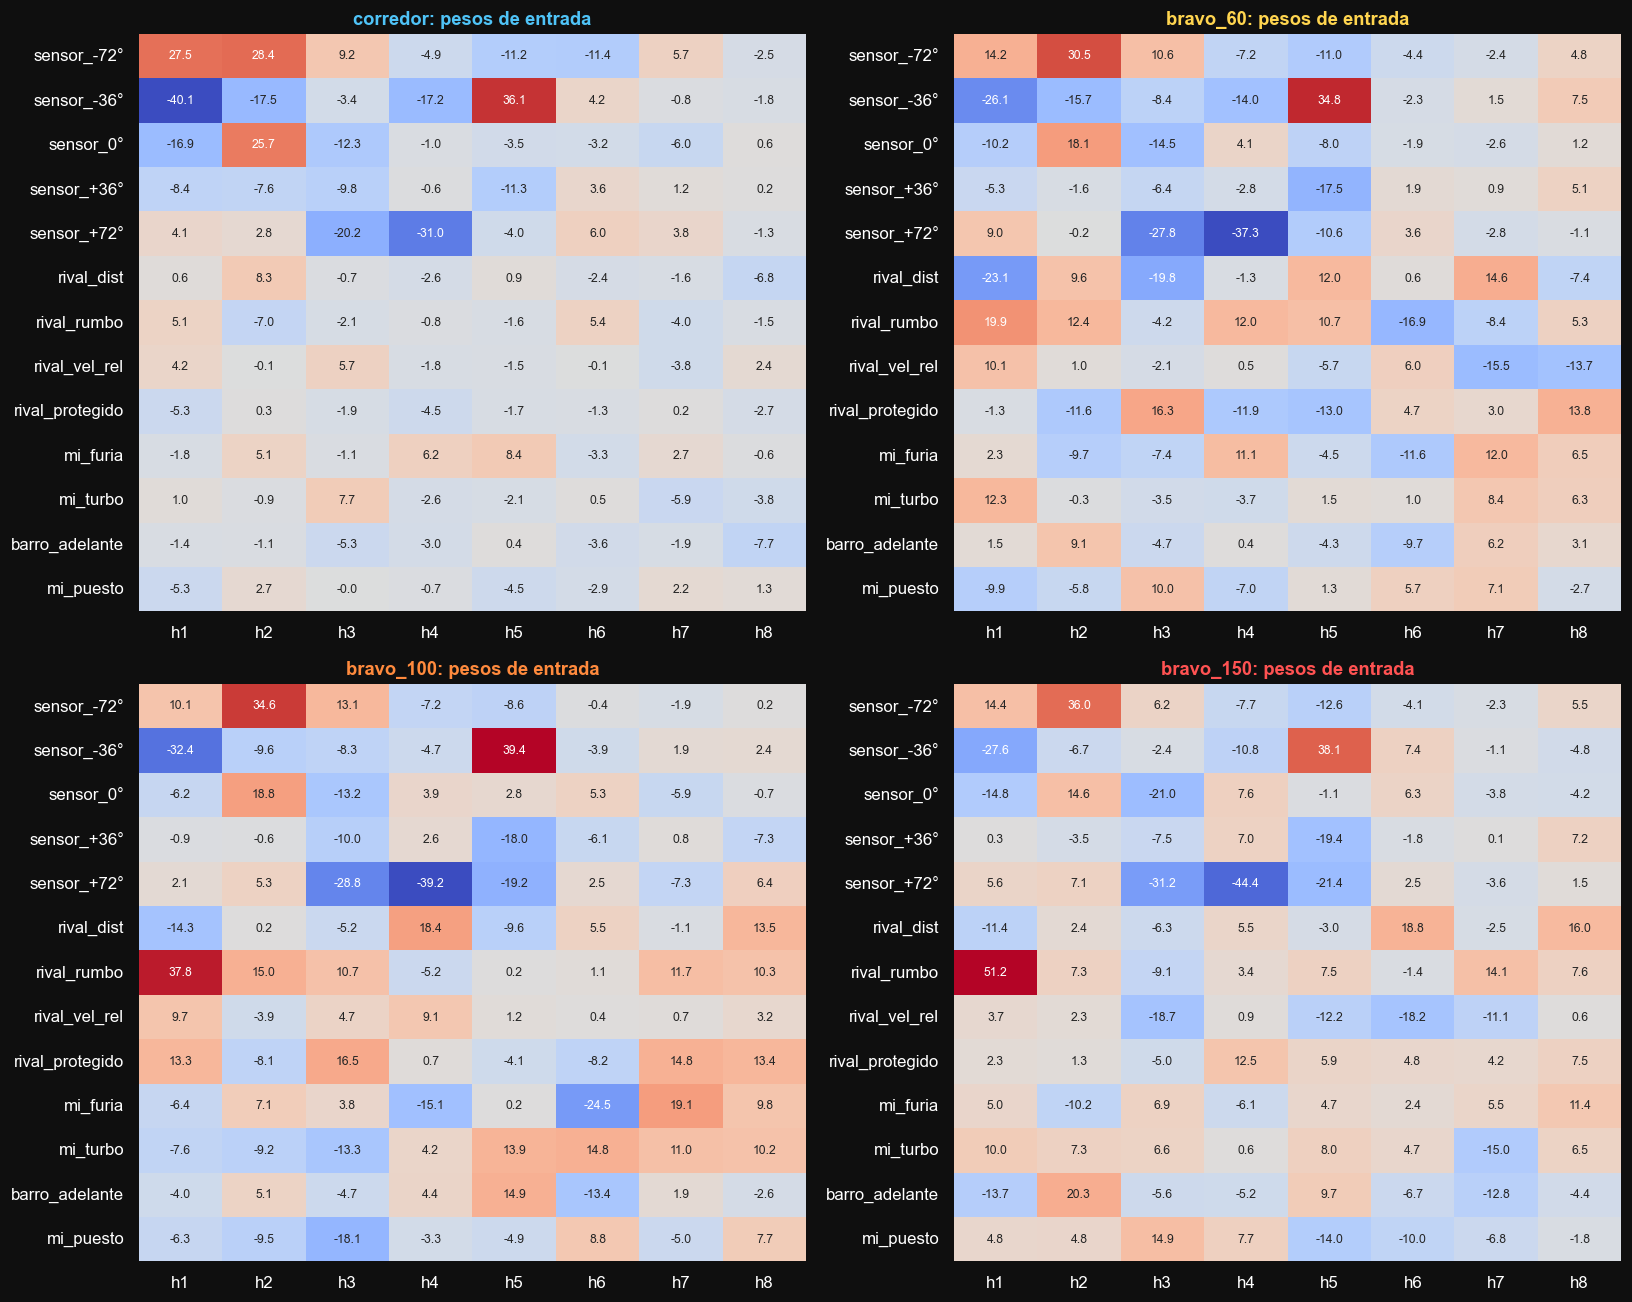

,corredor,bravo_60,bravo_100,bravo_150
sensor_-72°,16.0%,9.8%,9.2%,9.7%
sensor_-36°,21.4%,12.7%,12.3%,11.3%
sensor_0°,12.2%,7.0%,5.9%,7.2%
sensor_+36°,6.9%,5.2%,5.3%,5.3%
sensor_+72°,13.8%,12.5%,12.4%,13.4%
rival_dist,4.1%,9.7%,6.9%,6.5%
rival_rumbo,4.1%,8.9%,10.4%,12.6%
rival_vel_rel,3.1%,6.3%,3.5%,7.1%
rival_protegido,2.9%,7.8%,7.3%,4.1%
mi_furia,4.5%,6.4%,8.6%,4.6%


In [3]:
INPUTS = ['sensor_-72°', 'sensor_-36°', 'sensor_0°', 'sensor_+36°', 'sensor_+72°', 'rival_dist', 'rival_rumbo',
          'rival_vel_rel', 'rival_protegido', 'mi_furia', 'mi_turbo', 'barro_adelante', 'mi_puesto']
brains = {m: json.load(open(f'caballos_{m}.json'))[0] for m in MODELOS}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (p, b) in zip(axes.flat, brains.items()):
    W = np.array(b[0]['W'])
    lim = np.abs(W).max()
    sns.heatmap(W, ax=ax, cmap='coolwarm', center=0, vmin=-lim, vmax=lim, annot=True, fmt='.1f',
                yticklabels=INPUTS, xticklabels=[f'h{j+1}' for j in range(W.shape[1])], cbar=False,
                annot_kws={'size': 8})
    ax.set_title(f'{p}: pesos de entrada', fontweight='bold', color=MODELO_COLOR[p])
plt.tight_layout(); plt.savefig(OUT / '02_pesos_entrada.png'); plt.show()

# Importancia relativa de cada entrada = norma de su fila de pesos
imp = pd.DataFrame({p: np.linalg.norm(np.array(b[0]['W']), axis=1) for p, b in brains.items()}, index=INPUTS)
(imp / imp.sum()).round(3).style.format('{:.1%}').background_gradient(cmap='Reds', axis=None)

## 3. Inferencia: ¿cómo reacciona la red cuando ve a un rival?

Ponemos a la red en una recta despejada (los 5 sensores en 1.0, sin barro, a mitad de pelotón) y movemos al rival alrededor del caballo
(rumbo de -180° a +180°) a corta distancia. Si la dirección de giro tiene **el mismo signo** que el
rumbo del rival, el caballo **gira hacia él** (lo persigue); si tiene signo contrario, lo esquiva.

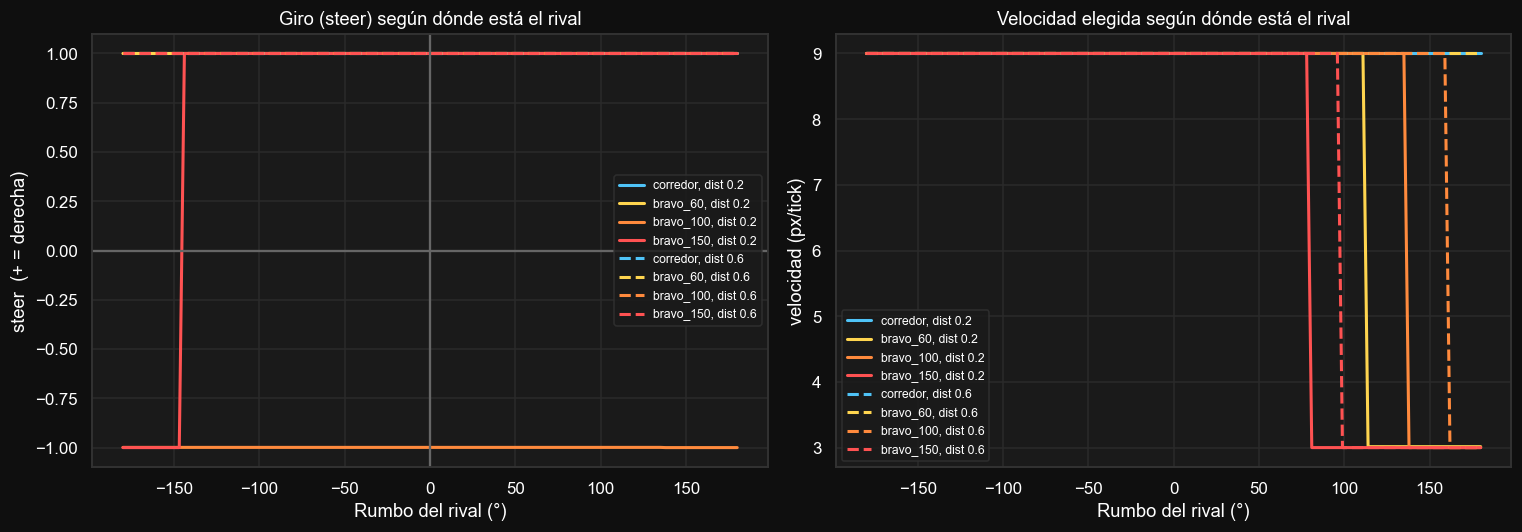

corredor : gira hacia el rival en el 49% de los rumbos frontales
bravo_60 : gira hacia el rival en el 49% de los rumbos frontales
bravo_100: gira hacia el rival en el 49% de los rumbos frontales
bravo_150: gira hacia el rival en el 49% de los rumbos frontales


In [4]:
def predict(brain, x):
    for layer in brain:
        x = np.tanh(np.asarray(x) @ np.array(layer['W']) + np.array(layer['b']))
    return x

def entorno(**kw):
    # Vector de 13 entradas: recta despejada, rival lejos, sin efectos, a mitad de pelotón
    base = dict(zip(INPUTS, [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0.5]))
    base.update(kw)
    return [base[k] for k in INPUTS]

rumbos = np.linspace(-1, 1, 121)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for dist, ls in [(0.2, '-'), (0.6, '--')]:
    for p, b in brains.items():
        out = np.array([predict(b, entorno(rival_dist=dist, rival_rumbo=r)) for r in rumbos])
        axes[0].plot(rumbos * 180, out[:, 0], ls, color=MODELO_COLOR[p], lw=2, label=f'{p}, dist {dist}')
        axes[1].plot(rumbos * 180, (out[:, 1] + 1) * 3 + 3, ls, color=MODELO_COLOR[p], lw=2, label=f'{p}, dist {dist}')
axes[0].axhline(0, color='#666'); axes[0].axvline(0, color='#666')
axes[0].set(title='Giro (steer) según dónde está el rival', xlabel='Rumbo del rival (°)', ylabel='steer  (+ = derecha)')
axes[1].set(title='Velocidad elegida según dónde está el rival', xlabel='Rumbo del rival (°)', ylabel='velocidad (px/tick)')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '03_reaccion_rival.png'); plt.show()

# Fracción de rumbos (rival por delante, ±90°) en los que la red gira HACIA el rival
front = np.abs(rumbos) <= 0.5
for p, b in brains.items():
    steer = np.array([predict(b, entorno(rival_dist=0.2, rival_rumbo=r))[0] for r in rumbos])
    hacia = np.mean(np.sign(steer[front]) == np.sign(rumbos[front]))
    print(f'{p:9s}: gira hacia el rival en el {hacia:.0%} de los rumbos frontales')

## 3b. ¿La red decide embestir según su entorno?

Nadie le dice al caballo "embiste". Medimos dos cosas en entornos simulados al azar
(sensores, rival, barro, efectos y puesto aleatorios):

1. **Sensibilidad**: cuánto cambia la decisión (giro + acelerador) al mover un poco cada entrada.
   Si una entrada no importa, la red la ignora; si importa, la está usando para decidir.
2. **Agresión**: con un rival adelante y cerca, qué fracción de las veces la red gira **hacia** él y acelera,
   en distintas situaciones (normal, con furia, rival con escudo, yendo primero o último).

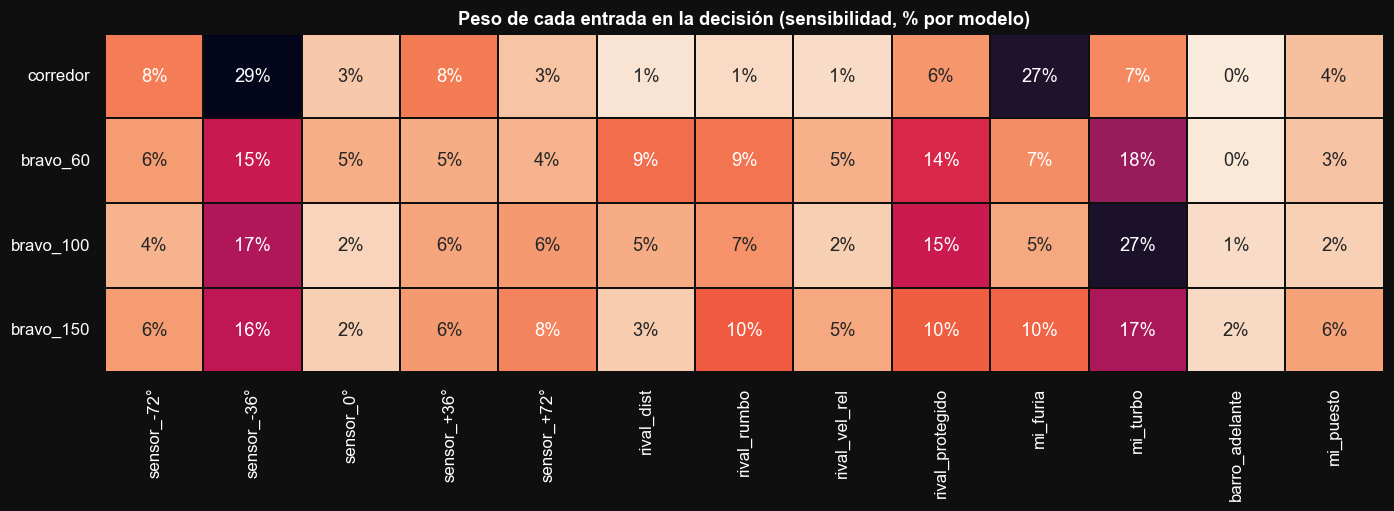

In [5]:
rng = np.random.default_rng(0)
N = 4000
def entornos_al_azar(n):
    X = np.column_stack([
        rng.uniform(0.15, 1, (n, 5)),                                  # sensores
        rng.uniform(0, 1, n), rng.uniform(-1, 1, n), rng.uniform(-0.4, 0.4, n),  # rival dist, rumbo, vel
        rng.integers(0, 2, n), rng.integers(0, 2, n), rng.integers(0, 2, n),     # protegido, furia, turbo
        np.where(rng.random(n) < 0.7, 1, rng.uniform(0, 1, n)),         # barro adelante
        rng.uniform(0, 1, n),                                           # puesto
    ])
    return X
X = entornos_al_azar(N)
BINARIAS = {'rival_protegido', 'mi_furia', 'mi_turbo'}
sens = {}
for m, b in brains.items():
    y0 = predict(b, X)
    row = []
    for j, name in enumerate(INPUTS):
        X2 = X.copy()
        X2[:, j] = 1 - X2[:, j] if name in BINARIAS else np.clip(X2[:, j] + 0.25, -1, 1)
        row.append(np.abs(predict(b, X2) - y0).sum(axis=1).mean())
    sens[m] = row
sens = pd.DataFrame(sens, index=INPUTS).T

plt.figure(figsize=(15, 4))
sns.heatmap(sens.div(sens.sum(axis=1), axis=0), annot=True, fmt='.0%', cmap='rocket_r', cbar=False, linewidths=1, linecolor='#0f0f0f')
plt.title('Peso de cada entrada en la decisión (sensibilidad, % por modelo)', fontweight='bold'); plt.yticks(rotation=0)
plt.savefig(OUT / '03b_sensibilidad.png'); plt.show()

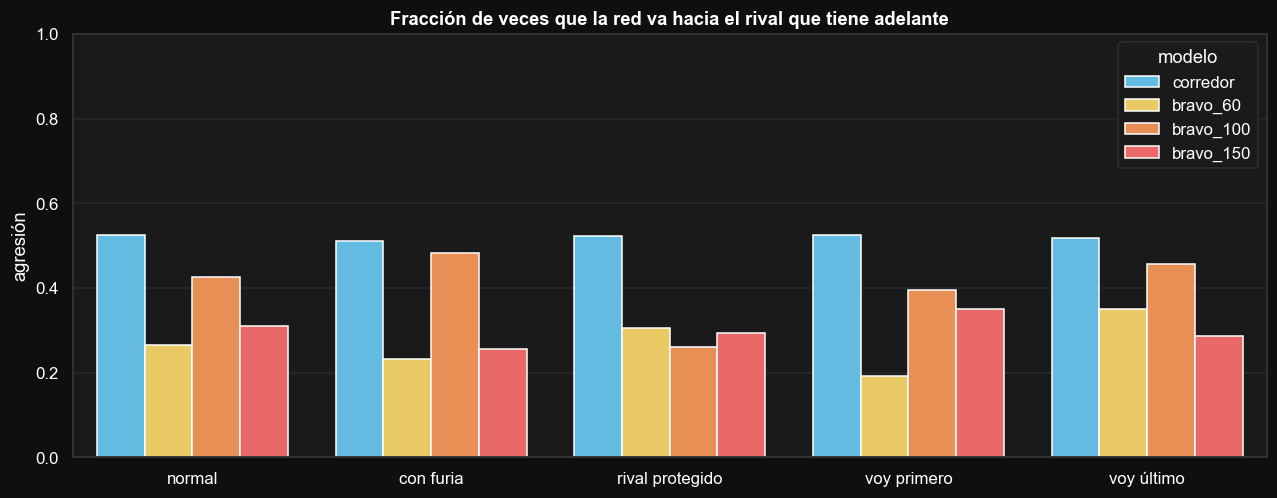

escenario,normal,con furia,rival protegido,voy primero,voy último
modelo,,,,,
corredor,0.52,0.51,0.52,0.52,0.52
bravo_60,0.27,0.23,0.30,0.19,0.35
bravo_100,0.42,0.48,0.26,0.39,0.46
bravo_150,0.31,0.25,0.29,0.35,0.29


In [6]:
# Rival adelante (±60°) y cerca: ¿gira hacia él y acelera?
n = 3000
base_X = entornos_al_azar(n)
base_X[:, 5] = rng.uniform(0, 0.5, n)              # cerca
base_X[:, 6] = rng.uniform(-1/3, 1/3, n)           # adelante
base_X[:, 8:11] = 0
escenarios = {
    'normal': {},
    'con furia': {'mi_furia': 1},
    'rival protegido': {'rival_protegido': 1},
    'voy primero': {'mi_puesto': 0},
    'voy último': {'mi_puesto': 1},
}
filas = []
for m, b in brains.items():
    for esc, cambios in escenarios.items():
        Xe = base_X.copy()
        for k, v in cambios.items(): Xe[:, INPUTS.index(k)] = v
        out = predict(b, Xe)
        hacia = (np.sign(out[:, 0]) == np.sign(Xe[:, 6])) & (out[:, 1] > 0)
        filas.append({'modelo': m, 'escenario': esc, 'agresion': hacia.mean()})
agr = pd.DataFrame(filas)
plt.figure(figsize=(14, 5))
sns.barplot(data=agr, x='escenario', y='agresion', hue='modelo', palette=MODELO_COLOR, hue_order=MODELOS)
plt.title('Fracción de veces que la red va hacia el rival que tiene adelante', fontweight='bold')
plt.ylabel('agresión'); plt.xlabel(''); plt.ylim(0, 1)
plt.savefig(OUT / '03c_agresion.png'); plt.show()
agr.pivot(index='modelo', columns='escenario', values='agresion').reindex(MODELOS)[list(escenarios)].round(2)

## 4. Torneo: victorias por caballo

`torneo.js` corre carreras con los 6 caballos del juego en pistas aleatorias de los 3 tamaños, con la
"forma del día" aleatoria igual que en el juego, y en ~70 % de las carreras lanza un poder al azar sobre
un caballo al azar (modo caos), como haría un jugador.

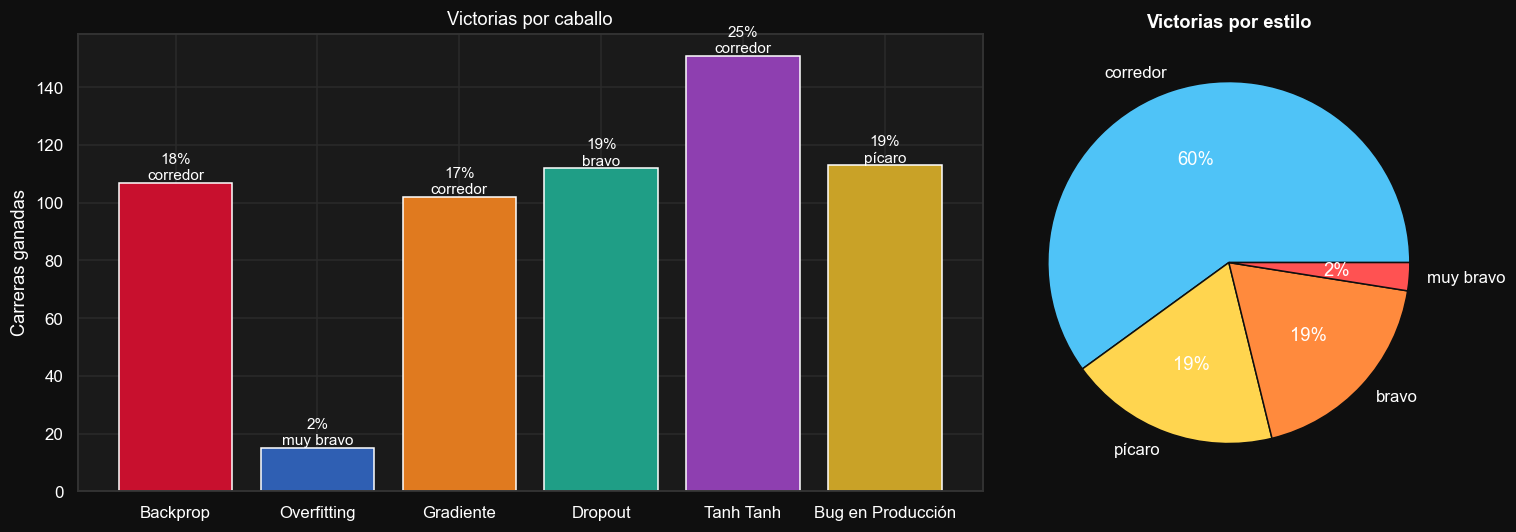

,estilo,prob_ganar,cuota_justa
nombre,,,
Backprop,corredor,0.178,5.6
Overfitting,muy bravo,0.025,40.0
Gradiente,corredor,0.170,5.9
Dropout,bravo,0.187,5.4
Tanh Tanh,corredor,0.252,4.0
Bug en Producción,pícaro,0.188,5.3


In [7]:
wins = torneo[torneo.gano].nombre.value_counts().reindex(HORSE_ORDER, fill_value=0)
estilo_de = torneo.drop_duplicates('nombre').set_index('nombre').estilo

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})
bars = axes[0].bar(wins.index, wins.values, color=[HORSE_COLOR[n] for n in wins.index], edgecolor='white')
for b, n in zip(bars, wins.index):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height() / torneo.carrera.nunique():.0%}\n{estilo_de[n]}",
                 ha='center', va='bottom', fontsize=10)
axes[0].set(title='Victorias por caballo', ylabel='Carreras ganadas')
pw = torneo[torneo.gano].estilo.value_counts()
axes[1].pie(pw.values, labels=pw.index, colors=[ESTILO_COLOR[p] for p in pw.index], autopct='%1.0f%%',
            textprops={'color': 'white'}, wedgeprops={'edgecolor': '#0f0f0f'})
axes[1].set_title('Victorias por estilo', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT / '04_victorias.png'); plt.show()

# Cuota justa (sin comisión) que pagaría cada caballo si las apuestas reflejaran su probabilidad real
prob = wins / torneo.carrera.nunique()
pd.DataFrame({'estilo': estilo_de.reindex(HORSE_ORDER), 'prob_ganar': prob.round(3),
              'cuota_justa': (1 / prob.replace(0, np.nan)).round(1)})

## 4b. ¿Arrancan todos con la misma probabilidad?

Dos mecanismos buscan que la carrera sea pareja al arrancar:
- **Sorteo de cajones**: cada carrera el carril de salida se sortea, así nadie tiene siempre el de adentro.
- **Hándicap** (`calibrar.js` → `handicap.json`): un multiplicador de velocidad por caballo, ajustado
  simulando cientos de carreras hasta que todos ganen ~1/6. Como en los hipódromos reales, el mejor carga más "peso".

Si funcionan, las victorias por cajón y por caballo deberían estar cerca de 1/6 (16.7 %). Lo comprobamos
con una prueba chi-cuadrado de bondad de ajuste en las carreras **sin poderes** (para medir solo a los caballos).

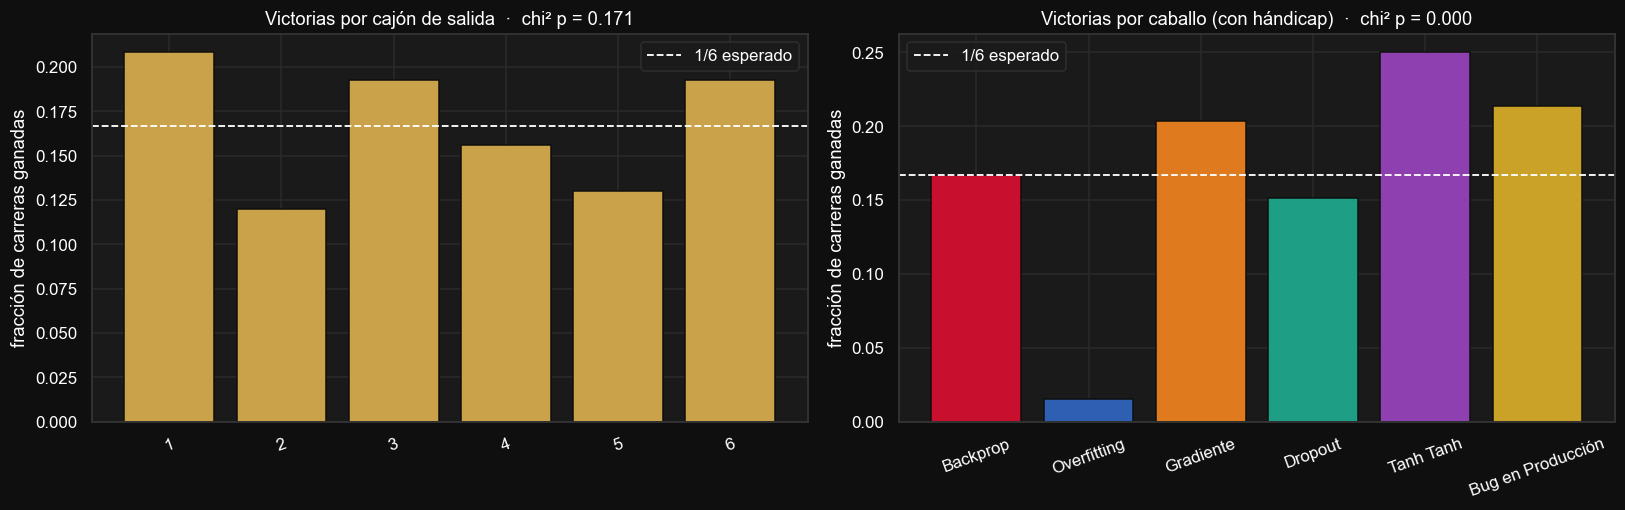

,hándicap,gana_%
Backprop,0.8358,16.7
Overfitting,1.2500,1.6
Gradiente,0.8320,20.3
Dropout,1.1902,15.1
Tanh Tanh,0.8509,25.0
Bug en Producción,0.9066,21.4


In [8]:
from scipy.stats import chisquare
limpio = torneo[torneo.poder_en_carrera == 'ninguno']
carreras = limpio.carrera.nunique()
por_cajon = limpio[limpio.gano].carril.value_counts().reindex(range(1, 7), fill_value=0)
por_caballo = limpio[limpio.gano].nombre.value_counts().reindex(HORSE_ORDER, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, serie, titulo, colores in [
        (axes[0], por_cajon, 'Victorias por cajón de salida', ['#c9a24a'] * 6),
        (axes[1], por_caballo, 'Victorias por caballo (con hándicap)', [HORSE_COLOR[n] for n in por_caballo.index])]:
    ax.bar([str(i) for i in serie.index], serie.values / carreras, color=colores, edgecolor='#0f0f0f')
    ax.axhline(1 / 6, color='white', ls='--', lw=1.2, label='1/6 esperado')
    p = chisquare(serie.values).pvalue
    ax.set(title=f'{titulo}  ·  chi² p = {p:.3f}', ylabel='fracción de carreras ganadas'); ax.legend()
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(OUT / '04b_salida_pareja.png'); plt.show()

handicap = json.load(open('handicap.json'))
pd.DataFrame({'hándicap': pd.Series(handicap), 'gana_%': (por_caballo / carreras * 100).round(1)})

## 5. Distribuciones de las métricas por estilo

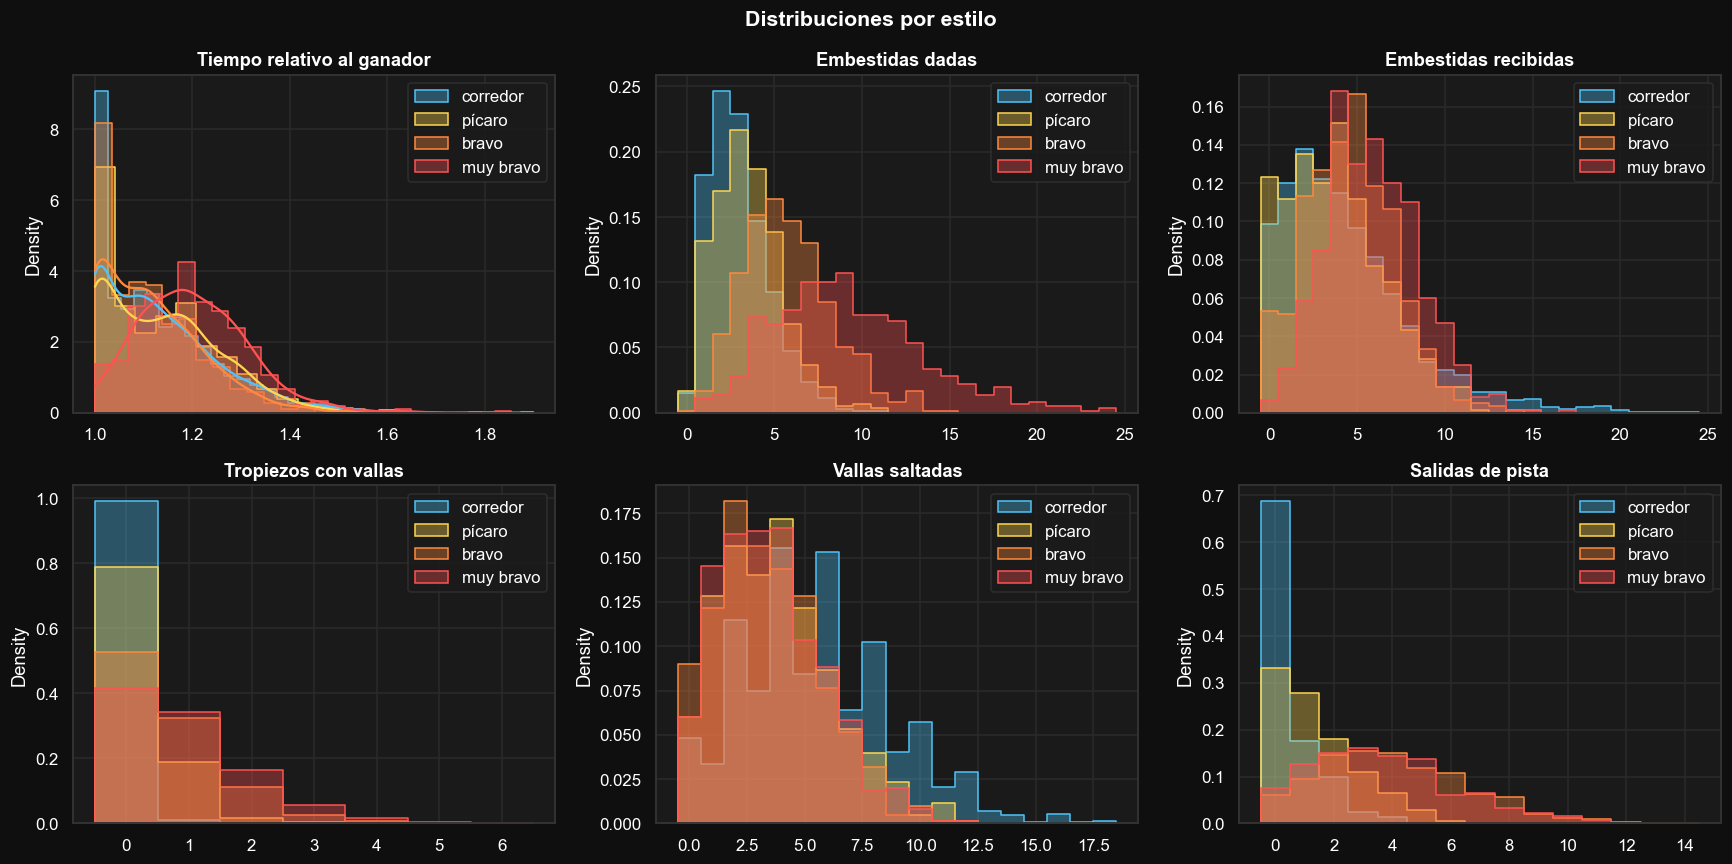

puesto       tiempo_rel       golpes_dados       golpes_recibidos  \
            mean   std       mean   std         mean   std             mean   
estilo                                                                        
corredor    3.14  1.67       1.13  0.12         3.01  1.72             4.44   
pícaro      3.46  1.75       1.13  0.12         3.54  1.93             3.77   
bravo       3.39  1.64       1.11  0.11         5.78  2.55             4.62   
muy bravo   4.74  1.22       1.20  0.11         9.25  4.25             5.89   

                tropiezos       saltos       salidas        
            std      mean   std   mean   std    mean   std  
estilo                                                      
corredor   3.70      0.01  0.10   5.55  3.26    0.51  0.91  
pícaro     2.73      0.24  0.50   3.78  2.42    1.41  1.42  
bravo      2.55      0.67  0.86   3.43  2.28    4.08  2.55  
muy bravo  2.65      0.93  1.02   3.54  2.27    3.70  2.45

In [9]:
cols = [('tiempo_rel', 'Tiempo relativo al ganador'), ('golpes_dados', 'Embestidas dadas'),
        ('golpes_recibidos', 'Embestidas recibidas'), ('tropiezos', 'Tropiezos con vallas'),
        ('saltos', 'Vallas saltadas'), ('salidas', 'Salidas de pista')]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (c, t) in zip(axes.flat, cols):
    for p in ESTILOS:
        d = torneo.loc[torneo.estilo == p, c].dropna()
        discrete = c != 'tiempo_rel'
        sns.histplot(d, ax=ax, color=ESTILO_COLOR[p], label=p, stat='density', alpha=0.35,
                     discrete=discrete, kde=not discrete, element='step')
    ax.set_title(t, fontweight='bold'); ax.set_xlabel(''); ax.legend()
plt.suptitle('Distribuciones por estilo', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig(OUT / '05_distribuciones.png'); plt.show()

torneo.groupby('estilo')[['puesto', 'tiempo_rel', 'golpes_dados', 'golpes_recibidos', 'tropiezos', 'saltos', 'salidas']].agg(['mean', 'std']).reindex(ESTILOS).round(2)

## 6. Boxplots por caballo

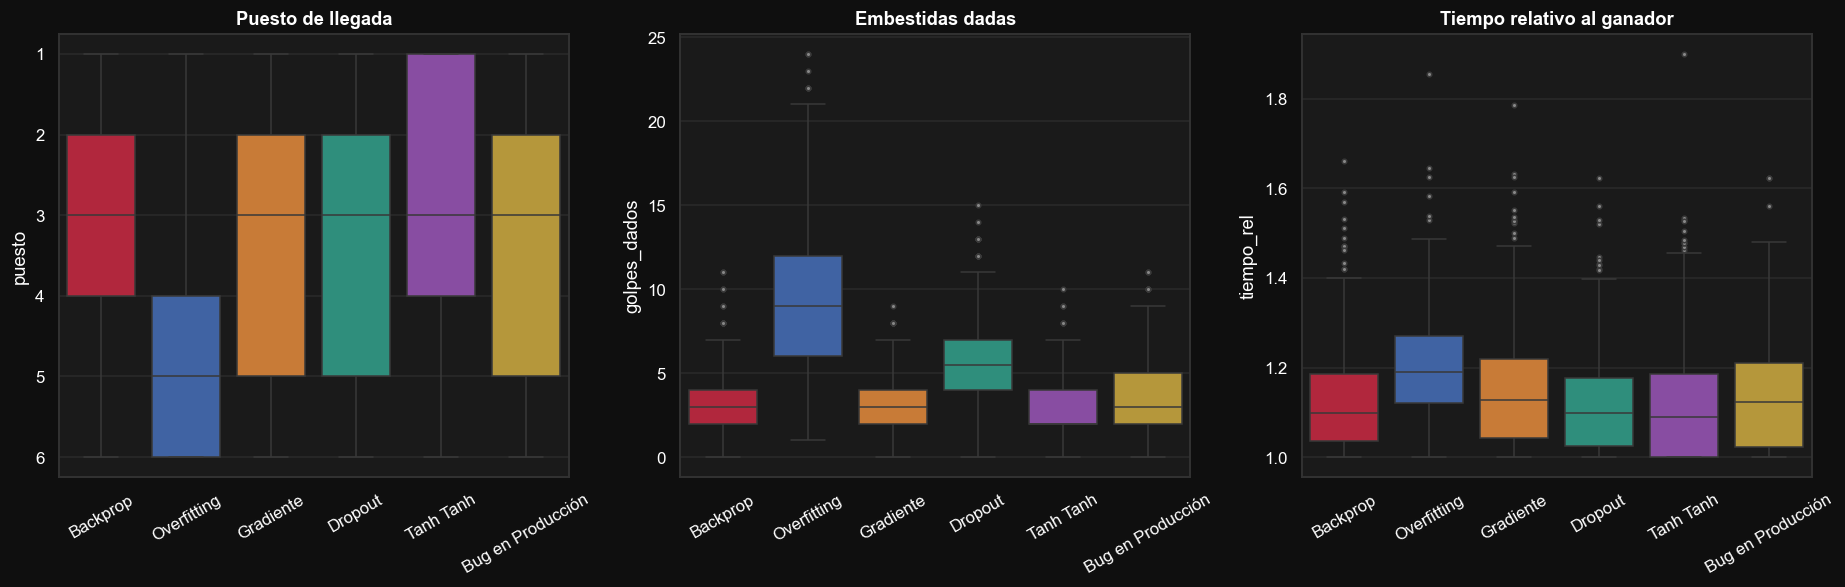

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (c, t) in zip(axes, [('puesto', 'Puesto de llegada'), ('golpes_dados', 'Embestidas dadas'), ('tiempo_rel', 'Tiempo relativo al ganador')]):
    sns.boxplot(data=torneo, x='nombre', y=c, order=HORSE_ORDER, palette=HORSE_COLOR, ax=ax,
                flierprops={'markerfacecolor': '#888', 'markersize': 3})
    ax.set_title(t, fontweight='bold'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
axes[0].invert_yaxis()
plt.tight_layout(); plt.savefig(OUT / '06_boxplots.png'); plt.show()

## 7. Efecto del largo de la pista

Las pistas largas tienen más obstáculos y más curvas. ¿Cambia quién gana y cuánto caos hay?

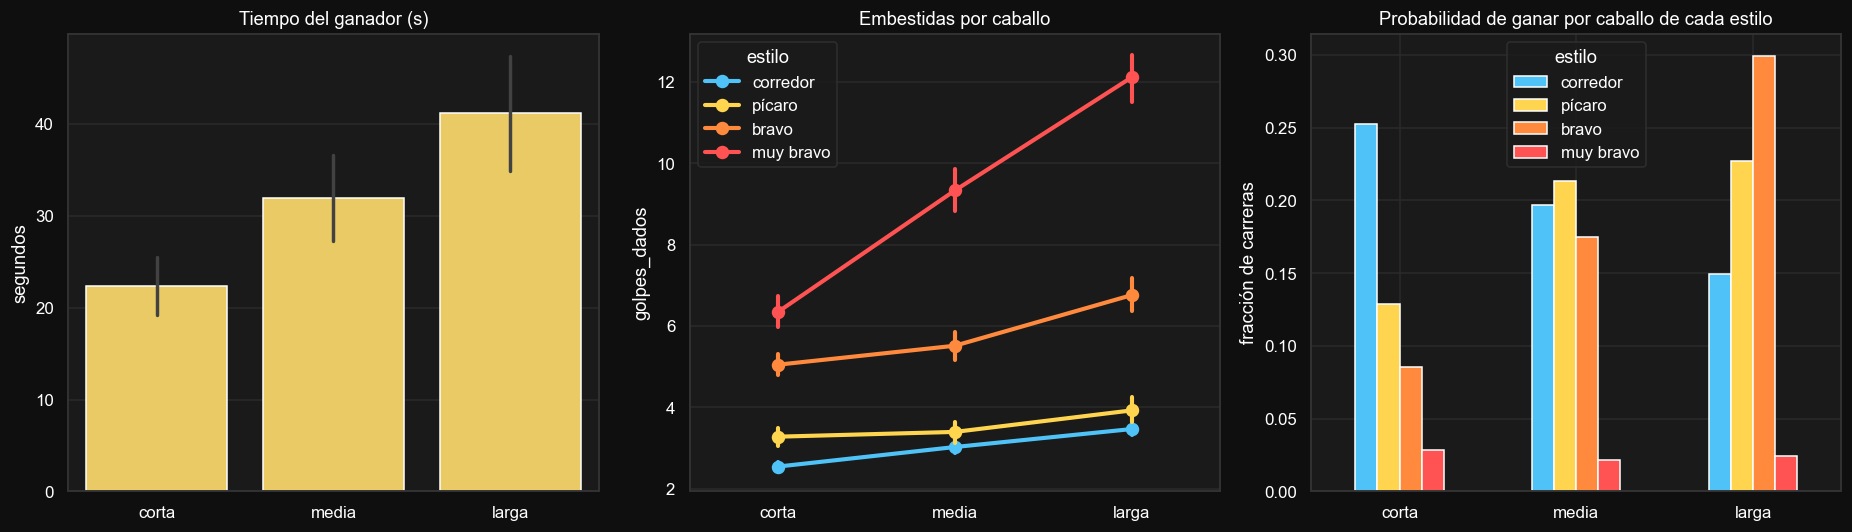

,largo_px,vueltas,vallas,tiempo_ganador
tamano,,,,
corta,2688.2,2,4.6,14.1
media,3887.4,2,6.7,19.6
larga,5123.0,2,8.9,27.5


In [11]:
orden_t = ['corta', 'media', 'larga']
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.barplot(data=torneo[torneo.gano], x='tamano', y='tiempo_s', order=orden_t, ax=axes[0], color='#ffd54f', errorbar='sd')
axes[0].set(title='Tiempo del ganador (s)', xlabel='', ylabel='segundos')
sns.pointplot(data=torneo, x='tamano', y='golpes_dados', hue='estilo', hue_order=ESTILOS, order=orden_t, palette=ESTILO_COLOR, ax=axes[1])
axes[1].set(title='Embestidas por caballo', xlabel='')
wr = torneo.groupby(['tamano', 'estilo']).gano.mean().unstack().reindex(orden_t)[ESTILOS]
wr.plot.bar(ax=axes[2], color=[ESTILO_COLOR[c] for c in wr.columns], rot=0)
axes[2].set(title='Probabilidad de ganar por caballo de cada estilo', xlabel='', ylabel='fracción de carreras')
plt.tight_layout(); plt.savefig(OUT / '07_por_pista.png'); plt.show()

torneo.groupby('tamano').agg(largo_px=('largo_pista', 'mean'), vueltas=('vueltas', 'first'), vallas=('obstaculos', 'mean'),
                             tiempo_ganador=('tiempo_s', 'min')).reindex(orden_t).round(1)

## 8. Matriz de correlación

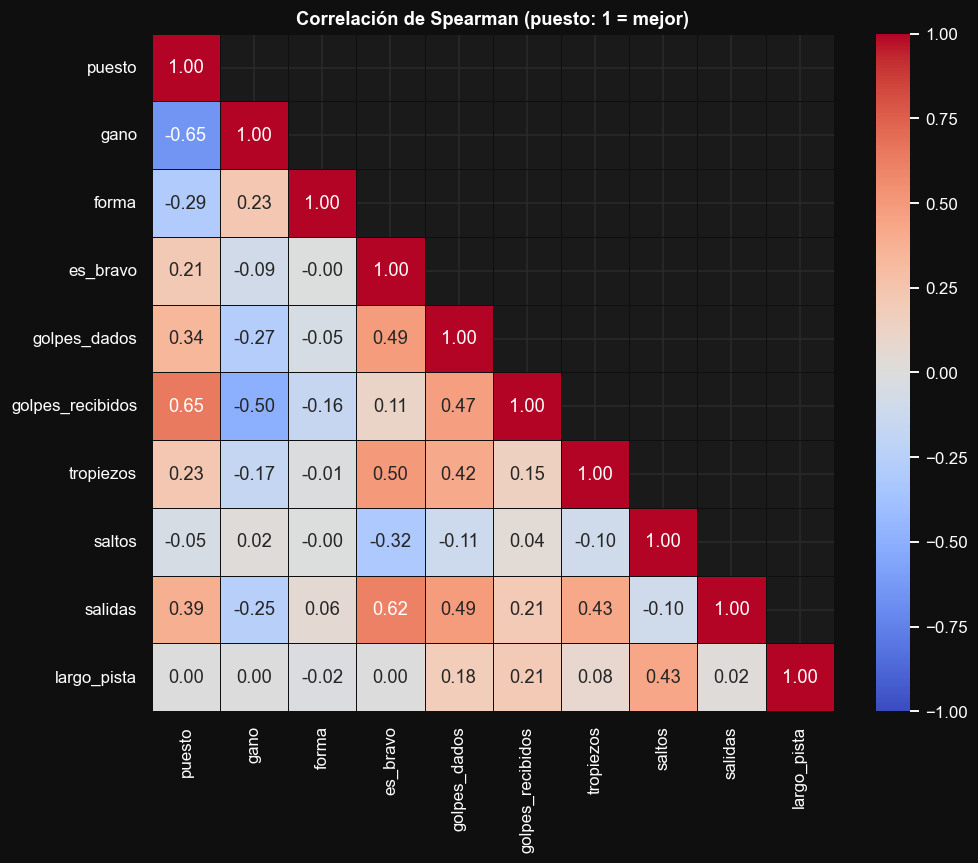

gano               -0.655
forma              -0.290
saltos             -0.053
largo_pista         0.000
es_bravo            0.213
tropiezos           0.234
golpes_dados        0.343
salidas             0.390
golpes_recibidos    0.647
Name: puesto, dtype: float64

In [12]:
num = torneo.assign(es_bravo=(torneo.perfil == 'bravo').astype(int), gano=torneo.gano.astype(int))[
    ['puesto', 'gano', 'forma', 'es_bravo', 'golpes_dados', 'golpes_recibidos', 'tropiezos', 'saltos', 'salidas', 'largo_pista']]
corr = num.corr(method='spearman')
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='#0f0f0f')
plt.title('Correlación de Spearman (puesto: 1 = mejor)', fontweight='bold')
plt.savefig(OUT / '08_correlacion.png'); plt.show()
corr['puesto'].drop('puesto').sort_values().round(3)

## 9. Pairplot

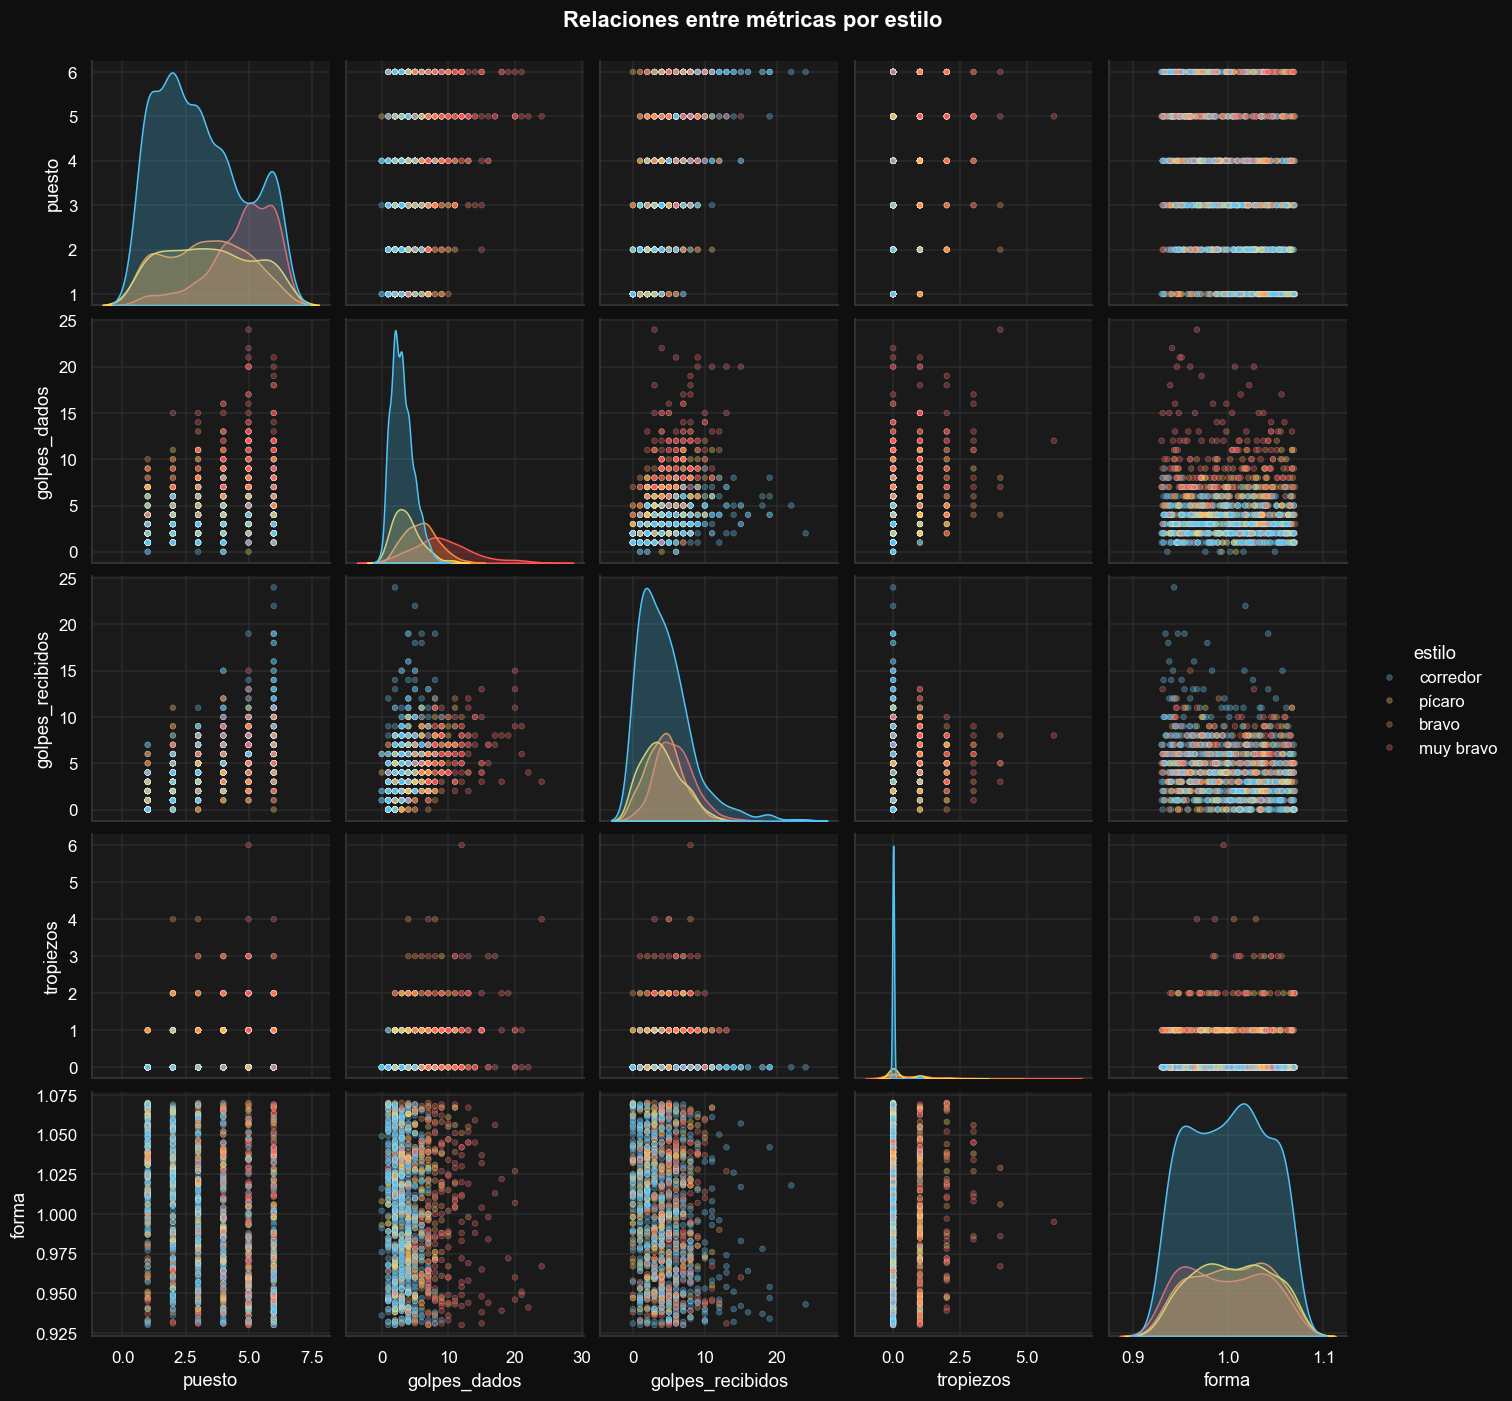

In [13]:
g = sns.pairplot(torneo[['puesto', 'golpes_dados', 'golpes_recibidos', 'tropiezos', 'forma', 'estilo']].sample(min(1200, len(torneo)), random_state=0),
                 hue='estilo', hue_order=ESTILOS, palette=ESTILO_COLOR, plot_kws={'alpha': 0.35, 's': 14}, diag_kind='kde')
g.figure.suptitle('Relaciones entre métricas por estilo', y=1.02, fontweight='bold')
g.savefig(OUT / '09_pairplot.png'); plt.show()

## 10. Violin: puesto por estilo y tamaño de pista

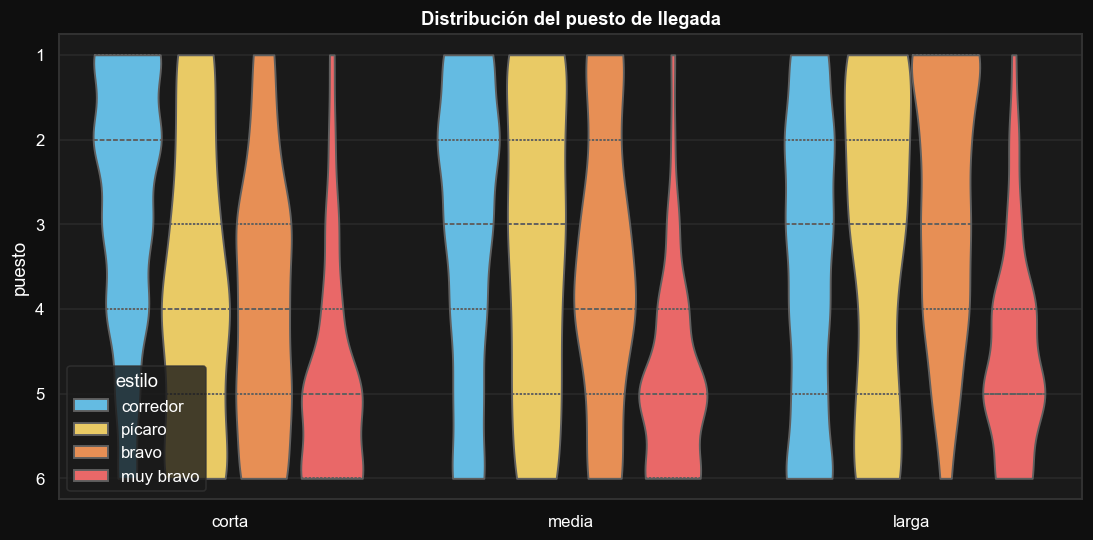

In [14]:
plt.figure(figsize=(12, 5.5))
sns.violinplot(data=torneo, x='tamano', y='puesto', hue='estilo', hue_order=ESTILOS, order=orden_t, inner='quart', palette=ESTILO_COLOR, cut=0)
plt.gca().invert_yaxis()
plt.title('Distribución del puesto de llegada', fontweight='bold'); plt.xlabel('')
plt.savefig(OUT / '10_violin.png'); plt.show()

## 11. Outliers: carreras desastrosas

Usamos el rango intercuartílico (IQR) del tiempo relativo dentro de cada perfil. Un caballo es outlier
si tarda más de `Q3 + 1.5·IQR`; veamos qué tienen en común esas carreras.

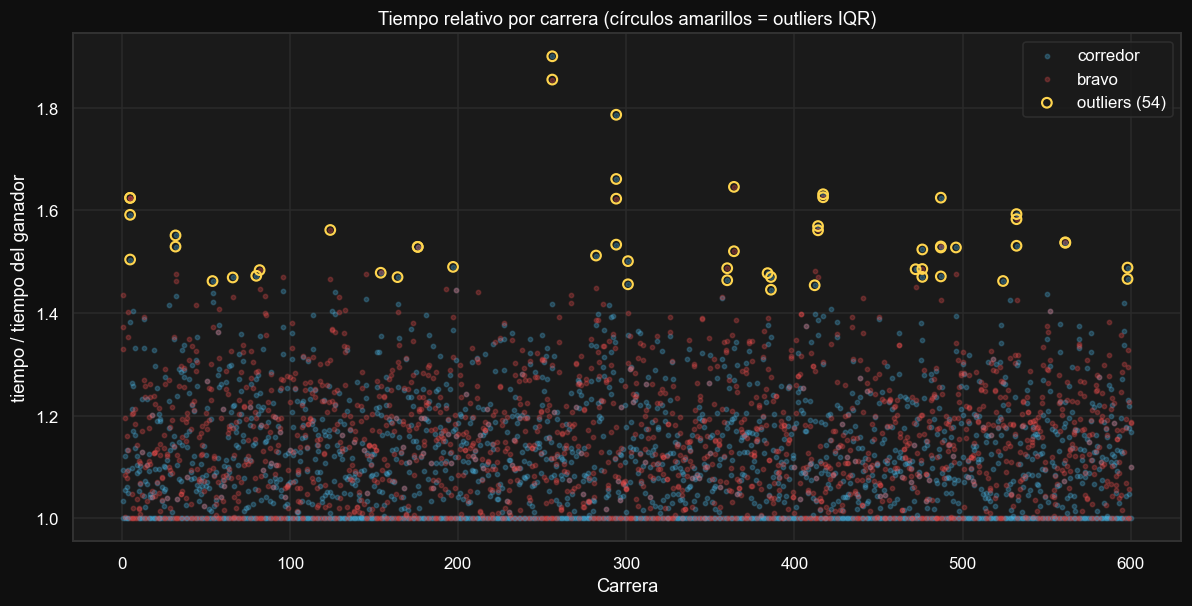

,outliers,resto
tropiezos,0.24,0.31
salidas,1.19,1.80
golpes_recibidos,7.31,4.56


In [15]:
def iqr_flag(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 1.5 * (q3 - q1)
torneo['outlier'] = torneo.groupby('perfil').tiempo_rel.transform(iqr_flag).fillna(False).astype(bool)

fig, ax = plt.subplots(figsize=(13, 6))
for p in ['corredor', 'bravo']:
    d = torneo[torneo.perfil == p]
    ax.scatter(d.carrera, d.tiempo_rel, s=8, alpha=0.25, color=PERFIL_COLOR[p], label=p)
o = torneo[torneo.outlier]
ax.scatter(o.carrera, o.tiempo_rel, s=40, facecolors='none', edgecolors='#ffd54f', lw=1.4, label=f'outliers ({len(o)})')
ax.set(title='Tiempo relativo por carrera (círculos amarillos = outliers IQR)', xlabel='Carrera', ylabel='tiempo / tiempo del ganador')
ax.legend(); plt.savefig(OUT / '11_outliers.png'); plt.show()

pd.DataFrame({
    'outliers': torneo[torneo.outlier][['tropiezos', 'salidas', 'golpes_recibidos']].mean(),
    'resto': torneo[~torneo.outlier][['tropiezos', 'salidas', 'golpes_recibidos']].mean(),
}).round(2)

In [16]:
# ¿Los outliers recibieron un poder? (porcentaje de filas que recibieron cada poder)
pd.crosstab(torneo.outlier, torneo.poder_recibido, normalize='index').mul(100).round(1)

poder_recibido,charco,escudo,furia,lazo,ninguno,rayo,vendas,zanahoria
outlier,,,,,,,,
False,1.6,1.6,1.7,1.4,88.6,1.7,1.6,1.7
True,1.9,0.0,0.0,3.7,90.7,0.0,1.9,1.9


## 12. ¿Cuánto vale cada poder? (balance del juego)

Comparamos a cada caballo **cuando recibe** un poder contra **ese mismo caballo** en carreras sin poderes.
Así el efecto no se confunde con que unos caballos son mejores que otros. Esto sirve para ajustar los costos
de `establo.js`: un poder que cambia mucho el resultado debería costar más.

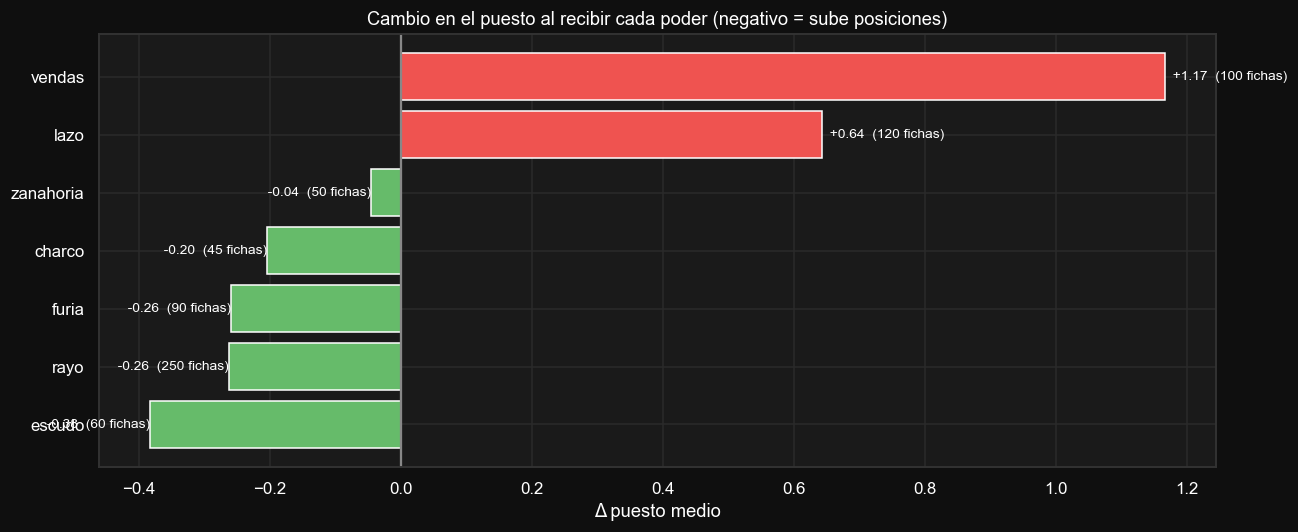

,n,delta_puesto,delta_prob_ganar,costo
poder_recibido,,,,
escudo,56,-0.383,0.065,60
rayo,60,-0.263,0.049,250
furia,61,-0.259,-0.017,90
charco,59,-0.205,0.027,45
zanahoria,62,-0.045,-0.000,50
lazo,53,0.643,-0.110,120
vendas,57,1.167,-0.156,100


In [17]:
base = torneo[torneo.poder_en_carrera == 'ninguno'].groupby('nombre').agg(base_puesto=('puesto', 'mean'), base_gano=('gano', 'mean'))
rec = torneo[torneo.poder_recibido != 'ninguno'].join(base, on='nombre')
rec['delta_puesto'] = rec.puesto - rec.base_puesto
rec['delta_gano'] = rec.gano.astype(float) - rec.base_gano

efecto = rec.groupby('poder_recibido').agg(n=('puesto', 'size'), delta_puesto=('delta_puesto', 'mean'),
                                          delta_prob_ganar=('delta_gano', 'mean')).sort_values('delta_puesto')
costos = {'zanahoria': 50, 'escudo': 60, 'vendas': 100, 'lazo': 120, 'furia': 90, 'charco': 45, 'rayo': 250}
efecto['costo'] = efecto.index.map(costos)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#66bb6a' if v < 0 else '#ef5350' for v in efecto.delta_puesto]
ax.barh(efecto.index, efecto.delta_puesto, color=colors)
ax.axvline(0, color='#888')
for i, (v, c) in enumerate(zip(efecto.delta_puesto, efecto.costo)):
    ax.text(v, i, f'  {v:+.2f}  ({c} fichas)', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set(title='Cambio en el puesto al recibir cada poder (negativo = sube posiciones)', xlabel='Δ puesto medio')
plt.tight_layout(); plt.savefig(OUT / '12_poderes.png'); plt.show()
efecto.round(3)

## 13. Resumen

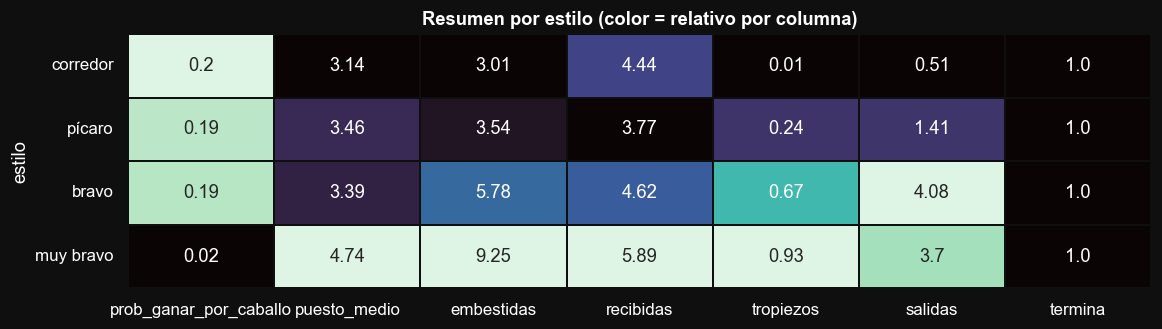

,prob_ganar_por_caballo,puesto_medio,embestidas,recibidas,tropiezos,salidas,termina
estilo,,,,,,,
corredor,0.200,3.136,3.006,4.436,0.011,0.513,1.0
pícaro,0.188,3.462,3.535,3.770,0.240,1.413,1.0
bravo,0.187,3.388,5.780,4.617,0.672,4.080,1.0
muy bravo,0.025,4.743,9.248,5.887,0.932,3.697,1.0


In [18]:
res = torneo.groupby('estilo').agg(
    prob_ganar_por_caballo=('gano', 'mean'), puesto_medio=('puesto', 'mean'),
    embestidas=('golpes_dados', 'mean'), recibidas=('golpes_recibidos', 'mean'),
    tropiezos=('tropiezos', 'mean'), salidas=('salidas', 'mean'), termina=('terminado', 'mean')).reindex(ESTILOS)
plt.figure(figsize=(12, 3))
norm = (res - res.min()) / (res.max() - res.min()).replace(0, 1)
sns.heatmap(norm, annot=res.round(2), fmt='', cmap='mako', cbar=False, linewidths=1, linecolor='#0f0f0f')
plt.title('Resumen por estilo (color = relativo por columna)', fontweight='bold'); plt.yticks(rotation=0)
plt.savefig(OUT / '13_resumen.png'); plt.show()
res.round(3)

## 14. Conclusiones

1. **La agresividad se puede entrenar.** Con el mismo punto de partida, subir el premio por embestida
   (60 → 100 → 150) produce caballos que embisten 3.5, 5.8 y 9.2 veces por carrera, contra ~3 de los corredores.
   Pero hay un precio: el más agresivo (Overfitting) pierde tanto tiempo persiguiendo rivales que casi nunca gana.
2. **La red decide según su entorno.** En la sección 3b los bravos cambian su conducta según la situación:
   bravo_100 va hacia el rival el 42 % de las veces, pero solo el 26 % si el rival tiene escudo o furia, y más cuando
   va último (46 %) que cuando va primero (39 %). Los corredores ignoran esas entradas (52 % en todos los escenarios),
   que es justo lo que su aptitud premiaba. La prueba de la sección 3 (rival en una recta vacía) no distingue entre
   modelos (49 % en todos): las redes están saturadas en ese escenario tan simple.
3. **Salida pareja.** Con sorteo de cajones y hándicap, cinco caballos ganan entre 15 % y 25 % en carreras limpias.
   Overfitting queda como el caballo sorpresa (~2 %): con más hándicap que ×1.25 se sale en las curvas,
   porque su red se entrenó a velocidad normal.
4. **Poderes.** Vendas y lazo son los que más mueven el resultado (hunden al caballo ~1.2 y ~0.6 puestos).
   Escudo, rayo y furia ayudan. La zanahoria casi no cambia nada aun con 4 s: es candidata a otro ajuste.
   Ojo: cada poder tiene ~60 casos, así que las diferencias pequeñas son ruido.
5. **Lo que más predice perder es recibir embestidas** (correlación 0.65 con el puesto), más que tropezar o salirse.
   En este juego, que te embistan sale más caro que una valla.